# Perceiving China: Cross-National Attitudes Towards Information Freedom and Censorship

## 1. Literature Review

### 1.1 Theorising Cross-National Perceptions: From Social Psychology to Critical Theory

Cross-national survey research illustrates that people in different countries place varying degrees of importance on freedom and self-expression, suggesting that a country's value profile may also shape how its citizens evaluate foreign states, and what forms of information control they deem as acceptable [[1]](#ref1). Social identity theory suggests that individuals derive part of their own self-concept from the groups they belong to, defining these 'in-groups' in contrast to relevant 'out-groups' [[2]](#ref2). Furthermore, critical approaches from the social sciences, such as those birthed by the 1970s "reflexive turn" within anthropology [[3]](#ref3) [[4]](#ref4), highlight that the act of framing others may also be contextualised as a lens onto one's own beliefs, values and assumptions [[5]](#ref5). Edward Said's *Orientalism* (1978) famously epitomised this shift by theorising how a Western imaginary of "the East" legitimises hierarchies between the self and "Other" [[6]](#ref6). Political scientists have extended this logic to the analysis of states, emphasising how nations construct an "Other" against which to articulate their own core values and anxieties [[7]](#ref7). Subsequent works have traced how these dynamics are reproduced in digital contexts, including forms of "techno-orientalism" in contemporary representations of Asian societies [[8]](#ref8) [[9]](#ref9) [[10]](#ref10) [[11]](#ref11). Such perspectives suggest that perceptions of China can be read not only as judgements about an external actor, but also as reflections of the societies doing the observing — an important reminder for dealing with cross-national data.

### 1.2 Digital Freedom and Perceptions of China 

China's global image is complex and contested [[12]](#ref12), with attitudes towards the republic varying considerably across global regions. China occupies a prominent position in debates on censorship, frequently portrayed as the best example of a digital authoritarian state in many liberal democracies [[13]](#ref13). Despite China having over 1.12 billion internet users and an internet penetration rate of around 79.7% [[14]](#ref14), it is consistently ranked among the most repressive countries for information freedom, receiving the lowest score for political rights and civil liberties from Freedom House [[15]](#ref15) and placing 178th out of 180 countries in the World Press Freedom Index in 2025 [[16]](#ref16). As subject to much controversy in Western media, the Chinese Communist Party retains extensive control over digital infrastructure [[17]](#ref17) [[18]](#ref18), online speech [[19]](#ref19), and information flows [[20]](#ref20) through advanced content moderation systems and internet censorship mechanisms such as the "Great Firewall" [[21]](#ref21) [[22]](#ref22) [[23]](#ref23). Nevertheless, both China and Western nations exhibit strong convergences in regards to regulating the internet, deploying new technologies, and confronting tensions around privacy, surveillance, content moderation, and information control [[24]](#ref24).

While much discourse in liberal democracies foregrounds a divide between authoritarian and democratic states, this framing often treats negative views of China as self-evident responses to objective governance practices rather than examining how domestic value orientations might shape such assessments. This Euro-American perspective is reflected in much existing scholarship on China, which places less emphasis on examining how perceptions of China differ according to the observers' own geographic position and values. Furthermore, while an analysis of non-Western perspectives has been increasingly addressed in fields such as anthropology, this is typically done through qualitative means, and by analysing individual countries in isolation rather than investigating broader geographic or value-based patterns across regions. Absent from this literature is a systematic examination of whether nations that prioritise freedom from censorship domestically perceive China differently than nations with alternative value frameworks.

## Methodology

### 2.1 Research Question and Hypothesis

Do cross-national perceptions of China correlate with attitudes toward freedom from censorship, and what larger geographic patterns emerge between nations? It is hypothesised that stronger support for internet, speech and press freedom will be associated with more negative perceptions of China, given that value commitments shape cross-national perceptions. Furthermore, favourability for China will likely be lower in Western liberal democracies, where existing research suggests that such freedoms are particularly valued.  

### 2.2 Data 

This analysis uses the Pew Spring Global Attitudes 2025 Survey, which collected data from a sample of n = 41,503 participants across 35 countries. The population of interest consists of all participants from these 35 countries and the dataset used contains 654 variables. This study focuses on variables measuring favourability towards China, measured on a 4-point ordinal scale: "very favourable" (1), "somewhat favourable" (2), "somewhat unfavourable" (3), and "very unfavourable" (4). It also examines the importance nations place on freedom from censorship: using the variables internet freedom, press freedom, and free speech. Freedom variables are similarly measured using a 4-point ordinal scale, with respondents indicating how important each freedom is. Freedom variables are first measured alongside one another, before being used to create a 'composite score' — given their grouping under 'censorship' within the Pew survey. Numeric labels (1–4) encode these scales, with lower values indicating more positive attitudes. Variables vary in their total number of valid responses. Non-response codes 8 ("don't know") and 9 ("refused") are also present in the dataset, but are excluded during analysis and are considered non-valid. For example, freedom variables have between 1,951 – 2,204 missing / non-valid responses (4.7% – 5.3% of n), which are dropped from the analysis. Country-level statistics are calculated as weighted proportions following Pew's methodological guidance to ensure balanced representativeness of demographics during comparisons. Statistical tests used have been selected for their appropriateness for working with ordinal data, and are non-parametric.

## 3. Analysis

### 3.1 China favourability and freedom values: an inverse relationship

In [258]:
import plotly as pl
import matplotlib.pyplot as plt
import matplotlib as mp
import seaborn as sns
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from scipy.stats import kruskal
from scipy.stats import ks_2samp
from matplotlib.patches import Ellipse

In [259]:
pew = pd.read_csv("pew_dataset.csv", dtype=str) 

In [260]:
# convert relevant columns to numeric

pew['weight'] = pd.to_numeric(pew['weight'], errors='coerce')
pew['age'] = pd.to_numeric(pew['age'], errors='coerce')  
pew['id'] = pd.to_numeric(pew['id'], errors='coerce')  
pew['country'] = pd.to_numeric(pew['country'], errors='coerce') 

# create a python dictionary, generating an additional 'country' column from country-codes for easier readability

country_code_map = {
    2: "Canada",
    3: "France",
    4: "Germany",
    5: "Greece",
    6: "Hungary",
    7: "Italy",
    8: "Netherlands",
    9: "Poland",
    10: "Spain",
    11: "Sweden",
    12: "UK",
    13: "Australia",
    14: "Bangladesh",
    15: "India",
    16: "Indonesia",
    17: "Japan",
    18: "Malaysia",
    19: "Philippines",
    20: "Singapore",
    21: "South Korea",
    22: "Sri Lanka",
    23: "Thailand",
    24: "Israel",
    25: "Tunisia",
    26: "Turkey",
    27: "Ghana",
    28: "Kenya",
    29: "Nigeria",
    30: "South Africa",
    31: "Argentina",
    32: "Brazil",
    33: "Chile",
    34: "Colombia",
    35: "Mexico",
    36: "Peru"
}

pew['country_name'] = pew['country'].map(country_code_map)

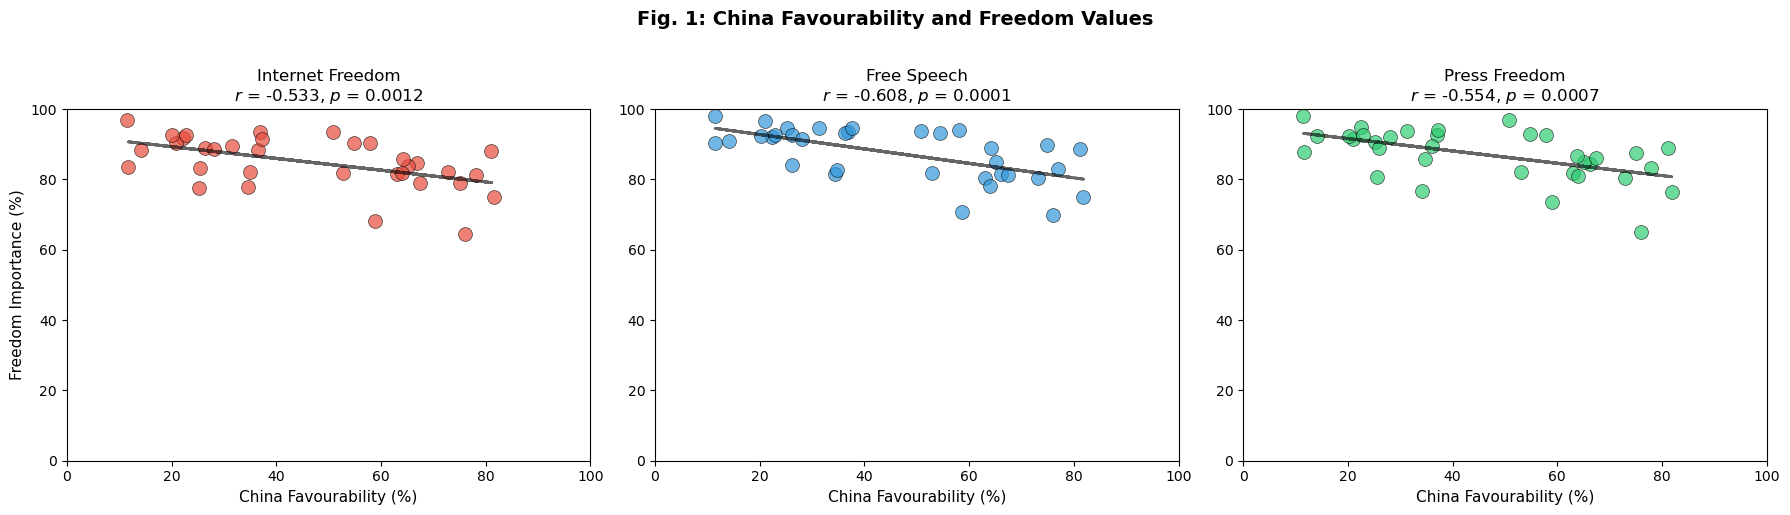

In [261]:
def calc_china_freedom_correlation(freedom_var):
    valid_data = pew[
        pew['fav_china'].isin(['1', '2', '3', '4']) & 
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        fav_china_favourable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
        fav_china_favourable_pct = (fav_china_favourable / total_weight) * 100
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = {
            'fav_china_favourable_pct': fav_china_favourable_pct,
            'freedom_important_pct': freedom_important_pct
        }
    
    return pd.DataFrame(country_stats).T

plot_df_internet = calc_china_freedom_correlation('internet_freedom')
plot_df_speech = calc_china_freedom_correlation('free_speech')
plot_df_press = calc_china_freedom_correlation('press_freedom')

# figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

from scipy import stats
from scipy.stats import spearmanr

# define colors for each plot
colors = ['#e74c3c', '#3498db', '#2ecc71']
datasets = [
    (plot_df_internet, 'Internet Freedom', 'internet_freedom'),
    (plot_df_speech, 'Free Speech', 'free_speech'),
    (plot_df_press, 'Press Freedom', 'press_freedom')
]

for idx, (plot_df, title, var_name) in enumerate(datasets):
    ax = axes[idx]
    
# scatter plot
    ax.scatter(plot_df['fav_china_favourable_pct'], 
               plot_df['freedom_important_pct'], 
               s=100, alpha=0.7, color=colors[idx], edgecolors='black', linewidth=0.5)
    
# trend line
    z = np.polyfit(plot_df['fav_china_favourable_pct'], 
                   plot_df['freedom_important_pct'], 1)
    p = np.poly1d(z)
    ax.plot(plot_df['fav_china_favourable_pct'], 
            p(plot_df['fav_china_favourable_pct']), 
            color='black', linestyle='--', alpha=0.6, linewidth=2)
    
# calculate correlation via spearman
    corr, p_val = spearmanr(plot_df['fav_china_favourable_pct'], 
                            plot_df['freedom_important_pct'])
    
# customise labels
    ax.set_xlabel('China Favourability (%)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Freedom Importance (%)', fontsize=11)
    ax.set_title(f'{title}\n$r$ = {corr:.3f}, $p$ = {p_val:.4f}', 
                 fontsize=12)
    ax.grid(False)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

plt.suptitle('Fig. 1: China Favourability and Freedom Values', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Correlations between importance of freedom from state censorship and favourability towards China were analysed. For each country $c$, ordinal responses were converted into weighted proportions $p_c$ representing the percentage of participants rating each freedom as "very" or "somewhat" important (values 1 or 2). Spearman's rank correlation coefficient $r$ was calculated between $p_c$ values, testing the null hypothesis $\mathrm{H}_0: ρ = 0$. P-values $p$ represent the probability that a correlation of magnitude ≥ $|r|$ would occur by chance if no true relationship existed between variables. For internet freedom, $r = -0.533$, $p = 0.0012$; free speech, $r = -0.60$, $p = 0.0001$; and press freedom, $r = -0.554$, $p = 0.0007$. P-values ranging from 0.0001 - 0.0012 indicates that observed correlations would occur by chance ≤ 0.12% of the time if no true relationship existed, providing strong evidence against $\mathrm{H}_0$. Strong negative correlations were observed: countries with higher favourability toward China tend to place lower importance on internet, speech, and press freedoms, consistent with the hypothesis. 

### 3.2 Favourability towards China across countries

/Users/teoboy/anaconda3/lib/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


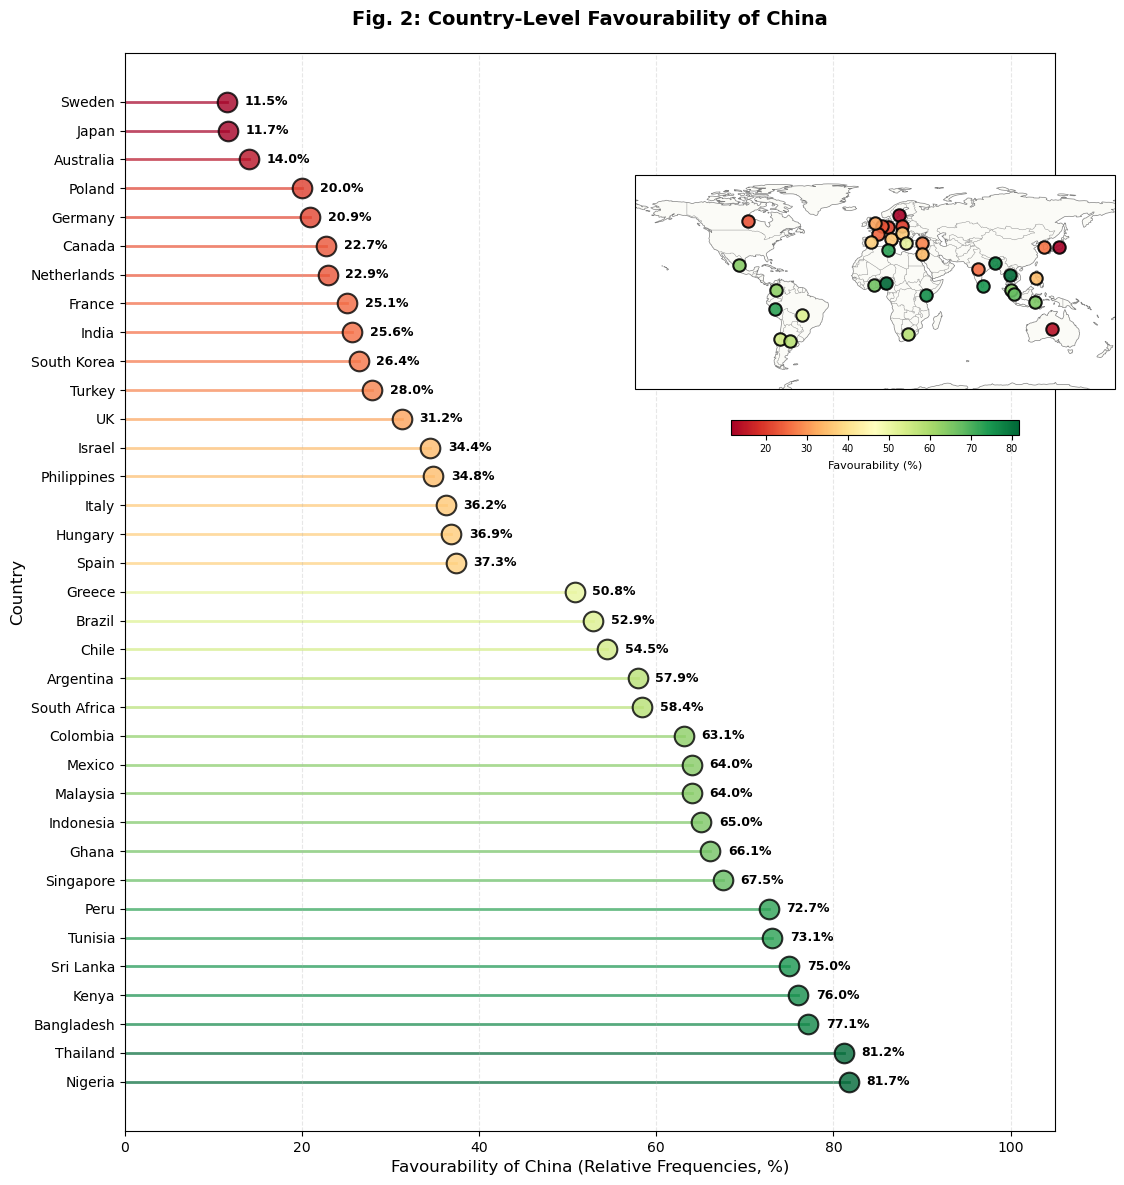

In [262]:
# filter to valid responses
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favourable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favourable_pct = (fav_china_favourable / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favourable_pct': fav_china_favourable_pct
    }

plot_df = pd.DataFrame(country_stats).T

# sort by china favourability
plot_df = plot_df.sort_values('fav_china_favourable_pct', ascending=True)

# implement cmap for colour gradient distinctions
cmap = plt.cm.RdYlGn  
norm = mcolors.Normalize(vmin=plot_df['fav_china_favourable_pct'].min(), 
                        vmax=plot_df['fav_china_favourable_pct'].max())

fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_favourable_pct']
    color = cmap(norm(china_val))  
    
    ax.plot([0, china_val], [i, i], color=color, linewidth=2, alpha=0.7, zorder=1)
    
    ax.scatter(china_val, i, s=200, color=color, alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    
    ax.text(china_val + 2, i, f'{china_val:.1f}%', 
            va='center', fontsize=9, fontweight='bold', zorder=4)

# create mini world map inset with cartopy
ax_map = fig.add_axes([0.55, 0.55, 0.40, 0.45], projection=ccrs.PlateCarree())

ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, color='gray')
ax_map.add_feature(cfeature.BORDERS, linewidth=0.3, color='gray')
ax_map.add_feature(cfeature.LAND, alpha=0.2)

country_coords = {
    'UK': (0, 54), 'France': (2, 46), 'Germany': (10, 51), 'Italy': (12, 42),
    'Spain': (-3, 40), 'Poland': (20, 52), 'Netherlands': (5, 52), 'Sweden': (18, 60),
    'Greece': (23, 39), 'Hungary': (20, 47),
    'Canada': (-95, 56), 'United States': (-95, 38),
    'Japan': (138, 36), 'South Korea': (127, 36), 'India': (77, 20), 'Indonesia': (120, -5),
    'Malaysia': (102, 4), 'Philippines': (121, 13), 'Singapore': (104, 1), 'Thailand': (101, 15),
    'Bangladesh': (90, 24), 'Sri Lanka': (81, 7),
    'Israel': (35, 31), 'Tunisia': (10, 34), 'Turkey': (35, 39),
    'South Africa': (25, -29), 'Ghana': (-1, 8), 'Kenya': (38, 0), 'Nigeria': (8, 9),
    'Brazil': (-55, -15), 'Argentina': (-64, -34), 'Chile': (-71, -33), 'Colombia': (-74, 4),
    'Peru': (-75, -10), 'Mexico': (-102, 23),
    'Australia': (133, -25)
}

for country in plot_df.index:
    if country in country_coords:
        lon, lat = country_coords[country]
        favourability = plot_df.loc[country, 'fav_china_favourable_pct']
        color = cmap(norm(favourability))  # Get color from gradient
        
        ax_map.scatter(lon, lat, s=80, c=[favourability], cmap=cmap, 
                      vmin=norm.vmin, vmax=norm.vmax, alpha=0.9, 
                      edgecolors='black', linewidth=1.5, zorder=5, 
                      transform=ccrs.PlateCarree())

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_map, orientation='horizontal', 
                   pad=0.05, shrink=0.6, aspect=20)
cbar.set_label('Favourability (%)', fontsize=8, labelpad=5)
cbar.ax.tick_params(labelsize=7)

ax_map.set_global()
ax_map.set_extent([-180, 180, -70, 90], crs=ccrs.PlateCarree())
ax_map.set_title(' ', fontsize=9, fontweight='bold', pad=5)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability of China (Relative Frequencies, %)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('Fig. 2: Country-Level Favourability of China',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 105)  
ax.set_xticks(np.arange(0, 101, 20))
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  

plt.show()

A second test measured general baseline favourability toward China across all 35 countries. Upon excluding 4,232 non-valid or missing responses (10.2% of n = 41,503), the final sample included 37,271 valid responses. Expressed as relative frequencies for each country $c$, favourability was similarly operationalised as the weighted proportion $p_c$ of participants reporting "very favourable" (1) or "somewhat favourable" (2). Fig. 2 demonstrated that baseline China favourability varied significantly across nations, ranging from 11.5% to 82.2%, with a median $M$ of 50.8%. Sweden (11.5%), Japan (11.7%) and Australia (14.0%) showed the lowest favourability, while Nigeria (81.7%), Thailand (81.2%) and Bangladesh (77.1%) exhibited the highest. Western nations clustered in the first two quartiles, with most in Q1. India (25.6%) and the Philippines (34.8%) were the only non-Western nations scoring below $M$. All countries above $M$ were non-Western nations. 

### 3.3 The US and EU are favoured to a greater extent than China

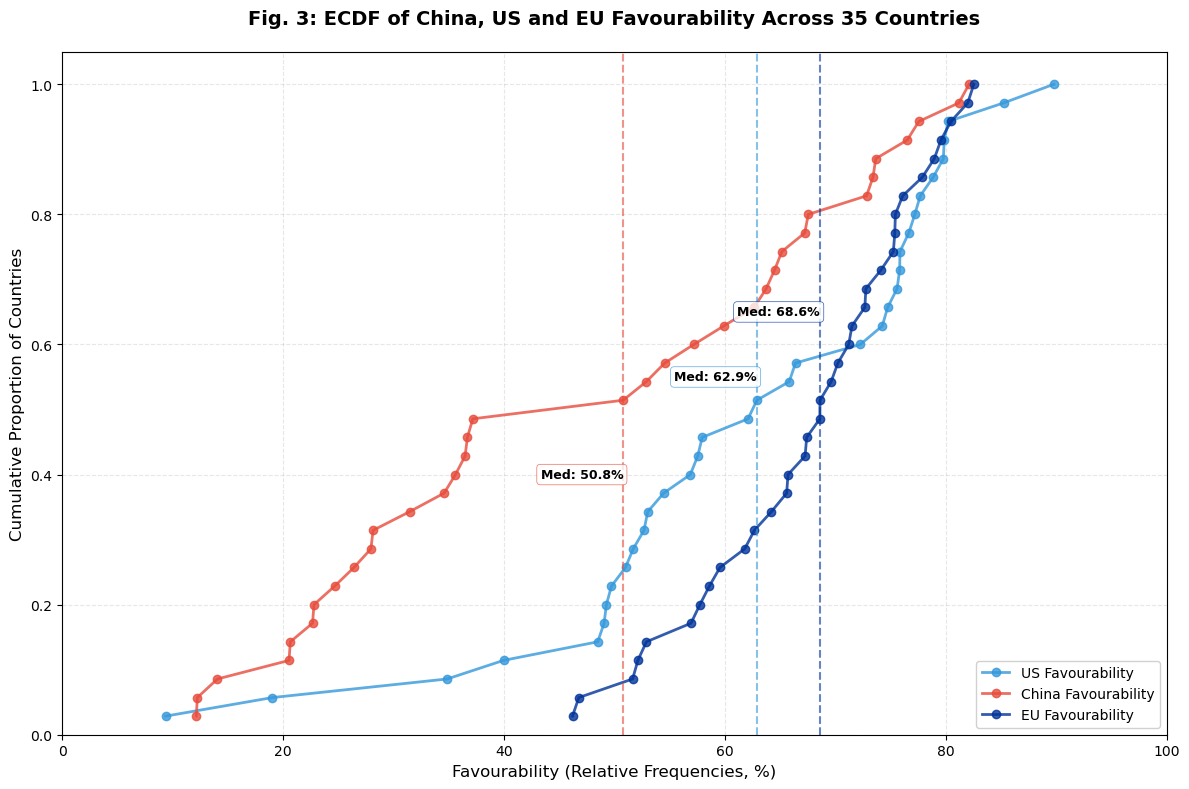

In [263]:
# filter variables
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['fav_china'].isin(['1', '2', '3', '4']) &
    pew['fav_eu'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'fav_china', 'fav_eu'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_us_favourable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_favourable_pct = (fav_us_favourable / total_weight) * 100
    
    fav_china_favourable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favourable_pct = (fav_china_favourable / total_weight) * 100
    
    fav_eu_favourable = country_data[country_data['fav_eu'].isin(['1', '2'])]['weight'].sum()
    fav_eu_favourable_pct = (fav_eu_favourable / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_favourable_pct': fav_us_favourable_pct,
        'fav_china_favourable_pct': fav_china_favourable_pct,
        'fav_eu_favourable_pct': fav_eu_favourable_pct
    }
plot_df = pd.DataFrame(country_stats).T

# create ECDF function
def ecdf(data):
    """Compute ECDF for a one-dimensional array of measurements."""
    n = len(data)
    x = np.sort(data)
    y = np.arange(1, n+1) / n
    return x, y

x_us, y_us = ecdf(plot_df['fav_us_favourable_pct'])
x_china, y_china = ecdf(plot_df['fav_china_favourable_pct'])
x_eu, y_eu = ecdf(plot_df['fav_eu_favourable_pct'])

fig, ax = plt.subplots(figsize=(12, 8))

ax.plot(x_us, y_us, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='US Favourability', color='#3498db', alpha=0.8)
ax.plot(x_china, y_china, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='China Favourability', color='#e74c3c', alpha=0.8)
ax.plot(x_eu, y_eu, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='EU Favourability', color='#003399', alpha=0.8)

# implement median lines
median_us = plot_df['fav_us_favourable_pct'].median()
median_china = plot_df['fav_china_favourable_pct'].median()
median_eu = plot_df['fav_eu_favourable_pct'].median()

ax.axvline(median_us, color='#3498db', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label
ax.axvline(median_china, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label
ax.axvline(median_eu, color='#003399', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label

ax.text(median_us, 0.55, f'Med: {median_us:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#3498db', linewidth=0.5))

ax.text(median_china, 0.4, f'Med: {median_china:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#e74c3c', linewidth=0.5))

ax.text(median_eu, 0.65, f'Med: {median_eu:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#003399', linewidth=0.5))

ax.set_xlabel('Favourability (Relative Frequencies, %)', fontsize=12)
ax.set_ylabel('Cumulative Proportion of Countries', fontsize=12)
ax.set_title('Fig. 3: ECDF of China, US and EU Favourability Across 35 Countries',
             fontsize=14, fontweight='bold', pad=20)

ax.legend(loc='lower right', framealpha=0.9, fontsize=10)

ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

# KS statistical tests 2 compare distributions
ks_stat_us_china, ks_p_us_china = ks_2samp(plot_df['fav_us_favourable_pct'], 
                                           plot_df['fav_china_favourable_pct'])
ks_stat_us_eu, ks_p_us_eu = ks_2samp(plot_df['fav_us_favourable_pct'], 
                                     plot_df['fav_eu_favourable_pct'])
ks_stat_china_eu, ks_p_china_eu = ks_2samp(plot_df['fav_china_favourable_pct'], 
                                           plot_df['fav_eu_favourable_pct'])

An ECDF analysis compared favourability distributions across three major powers (China, US, and EU). Percentile comparisons at the 25th, 50th, and 75th percentiles revealed China (27.2%, 50.8%, 66.2%), US (51.3%, 62.9%, 76.2%), and EU (60.7%, 68.6%, 75.3%), indicating that China's distribution shifted toward lower favourability across all quartiles. Range: China (12.1% - 82.1%); US (9.3% - 89.8%); and EU (46.2% - 82.5%). Kolmogorov-Smirnov (KS) tests were applied to compare ECDF distributions, supported by test statistic $D = max|F₁(x) - F₂(x)|$. KS tests highlighted that US and EU distributions were similar in distribution, whilst China's was more differentiated. China vs US: $D = 0.400$, $p = 0.0069$; China vs EU: $D = 0.486$, $p = 0.0004$; and US vs EU: $D = 0.257$, $p = 0.1991$. An unexpected finding emerged: China's favourability fell substantially below both US and EU favourability across the entire distribution - inclusive of non-Western nations.


### 3.4 Freedom from censorship is deemed more important in Western countries

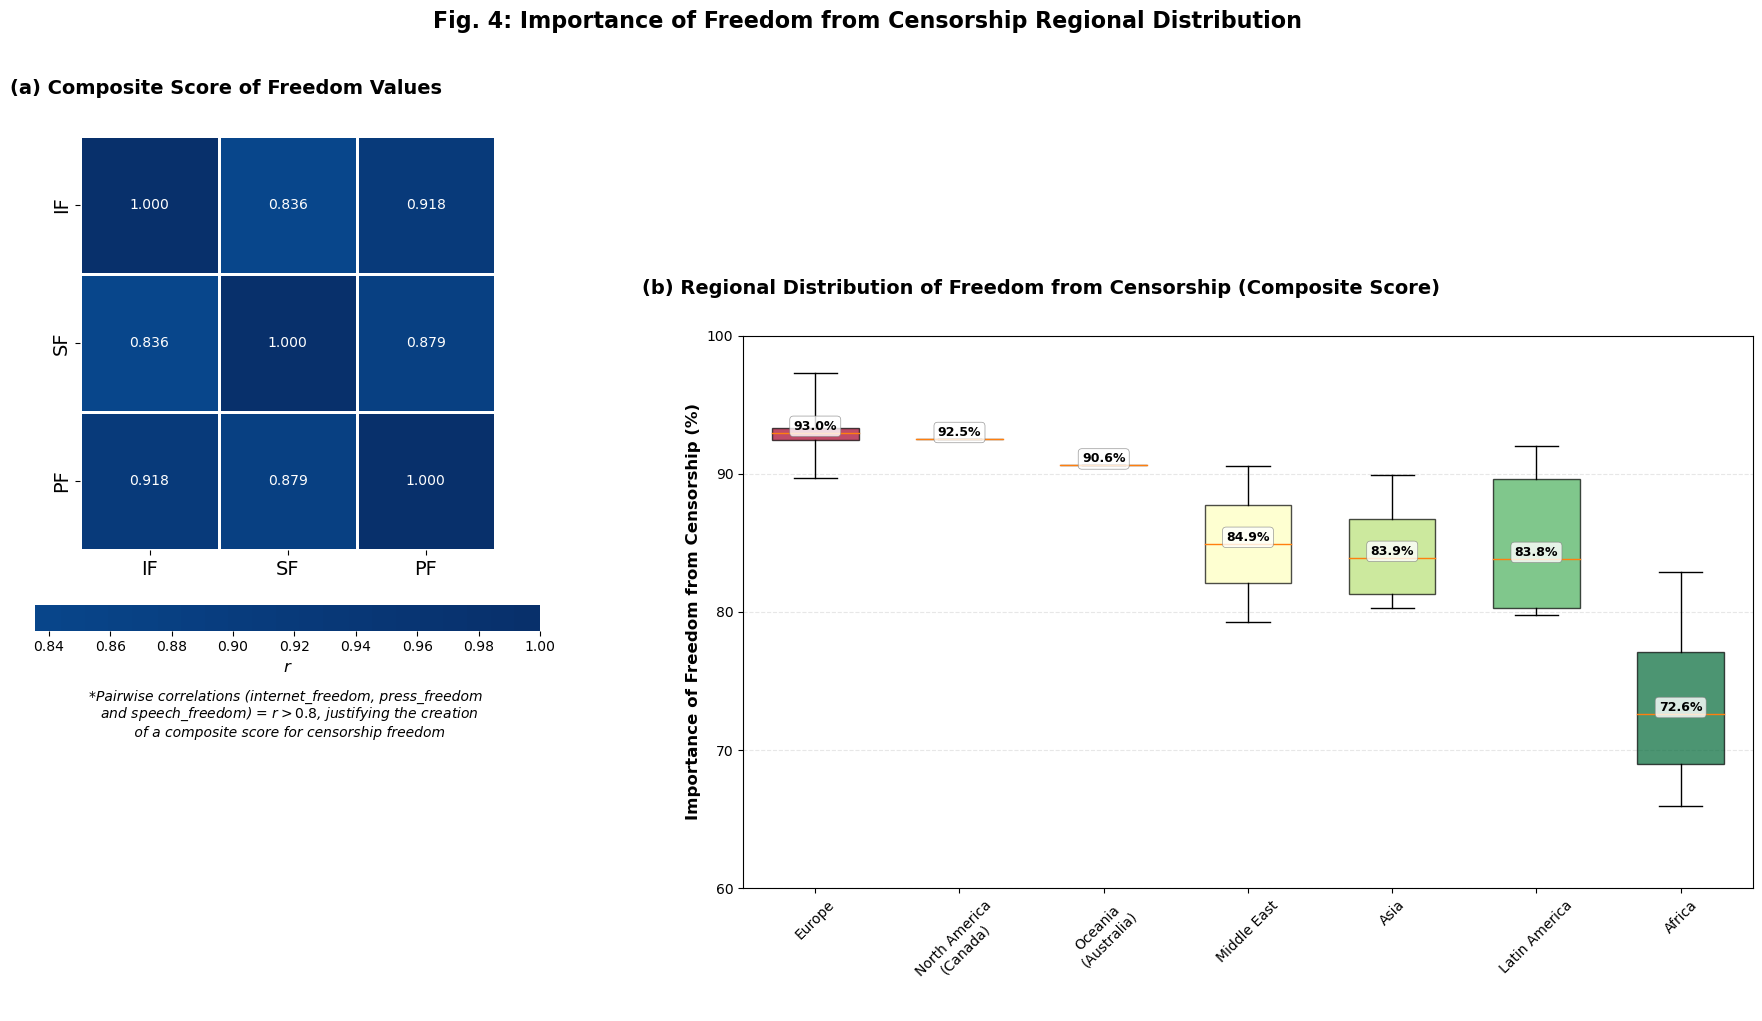

In [264]:
# (a) correlation matrix / composite score

def calc_freedom_importance(freedom_var):
    valid_data = pew[
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = freedom_important_pct
    
    return pd.Series(country_stats)

internet_scores = calc_freedom_importance('internet_freedom')
speech_scores = calc_freedom_importance('free_speech')
press_scores = calc_freedom_importance('press_freedom')

common_countries = internet_scores.index.intersection(speech_scores.index).intersection(press_scores.index)
internet_aligned = internet_scores[common_countries]
speech_aligned = speech_scores[common_countries]
press_aligned = press_scores[common_countries]

corr_matrix = pd.DataFrame({
    'Internet Freedom': internet_aligned,
    'Free Speech': speech_aligned,
    'Press Freedom': press_aligned
}).corr(method='spearman') 

# define region mapping
region_map = {
    'UK': 'Europe', 'France': 'Europe', 'Germany': 'Europe', 'Italy': 'Europe',
    'Spain': 'Europe', 'Netherlands': 'Europe', 'Sweden': 'Europe', 'Greece': 'Europe',
    'Poland': 'Europe', 'Hungary': 'Europe',
    'Canada': 'North America (Canada)',
    'Japan': 'Asia', 'South Korea': 'Asia', 'India': 'Asia', 'Indonesia': 'Asia',
    'Malaysia': 'Asia', 'Philippines': 'Asia', 'Singapore': 'Asia', 'Thailand': 'Asia',
    'Bangladesh': 'Asia', 'Sri Lanka': 'Asia',
    'Israel': 'Middle East', 'Turkey': 'Middle East', 'Tunisia': 'Middle East',
    'Ghana': 'Africa', 'Kenya': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Argentina': 'Latin America', 'Brazil': 'Latin America', 'Chile': 'Latin America',
    'Colombia': 'Latin America', 'Mexico': 'Latin America', 'Peru': 'Latin America',
    'Australia': 'Oceania (Australia)'
}

composite_scores = (internet_aligned + speech_aligned + press_aligned) / 3

composite_df = pd.DataFrame({
    'Country': composite_scores.index,
    'Composite_Freedom_Score': composite_scores.values,
    'Region': [region_map.get(country, 'Other') for country in composite_scores.index]
})

region_order = ['Europe', 'North America (Canada)', 'Oceania (Australia)', 'Middle East', 'Asia', 'Latin America', 'Africa']

box_data = []
box_labels = []

for region in region_order:
    region_data = composite_df[composite_df['Region'] == region]['Composite_Freedom_Score'].values
    if len(region_data) > 0:
        box_data.append(region_data)
        label = region.replace(' (', '\n(')
        box_labels.append(label)

# figure creation

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# (a) correlation matrix
ax_a = axes[0]

corr_matrix_renamed = corr_matrix.copy()
corr_matrix_renamed.columns = ['IF', 'SF', 'PF']
corr_matrix_renamed.index = ['IF', 'SF', 'PF']

sns.heatmap(corr_matrix_renamed, annot=True, fmt='.3f', cmap='Blues', center=0,
            square=True, linewidths=1, 
            cbar_kws={"shrink": 0.5, "orientation": "horizontal", "pad": 0.1}, 
            ax=ax_a, 
            xticklabels=True, yticklabels=True)  # Keep default labels

cbar = ax_a.collections[0].colorbar
cbar.set_label('$r$', fontsize=12)  # Increase from default (usually 10-12)
cbar.ax.xaxis.label.set_fontsize(12)

ax_a.tick_params(axis='both', labelsize=14)  # Increase from default (usually 10-12)

ax_a.set_title('(a) Composite Score of Freedom Values', fontsize=14, fontweight='bold', pad=30, loc='left', x=-0.17)

# * note
ax_a.text(0.5, -0.45, '*Pairwise correlations (internet_freedom, press_freedom \n and speech_freedom) = $r > 0.8$, justifying the creation \n of a composite score for censorship freedom',
          transform=ax_a.transAxes, fontsize=10, ha='center', 
          style='italic', color='black')

# (b) boxplot by region
ax_b = axes[1]

cmap_gradient = plt.cm.RdYlGn

bp = ax_b.boxplot(box_data, labels=box_labels, patch_artist=True,
                  widths=0.6, showmeans=False, meanline=False, whis=10.0)

for i, patch in enumerate(bp['boxes']):
    color_value = i / (len(bp['boxes']) - 1) if len(bp['boxes']) > 1 else 0
    color = cmap_gradient(color_value)
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

for i, (data, label) in enumerate(zip(box_data, box_labels)):
    median_val = np.median(data)
    x_pos = i + 1  
    ax_b.text(x_pos, median_val, f'{median_val:.1f}%', 
              ha='center', va='bottom', fontsize=9, fontweight='bold',
              bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray', linewidth=0.5))

ax_b.set_ylabel('Importance of Freedom from Censorship (%)', fontsize=12, fontweight='bold')
ax_b.set_xlabel(' ', fontsize=12, fontweight='bold')
ax_b.set_title('(b) Regional Distribution of Freedom from Censorship (Composite Score)', 
               fontsize=14, fontweight='bold', pad=30, loc='left', x=-0.10)
ax_b.tick_params(axis='x', rotation=45)
ax_b.grid(True, alpha=0.3, axis='y', linestyle='--')
ax_b.set_ylim(60, 100)
ax_b.set_yticks(np.arange(60, 101, 10)) 

# figure title
fig.suptitle('Fig. 4: Importance of Freedom from Censorship Regional Distribution', 
            fontsize=16, fontweight='bold', x=0.55, y=1.02)

plt.tight_layout()

# positional adjustment
ax_b_pos = ax_b.get_position()
ax_b.set_position([ax_b_pos.x0, ax_b_pos.y0 - 0.25, ax_b_pos.width, ax_b_pos.height])

# Statistical test: KS

if len(box_data) > 2:
    h_stat, p_val = kruskal(*box_data)

plt.show()



Given that the Pew survey grouped internet freedom, free speech, and press freedom under 'censorship', measuring the same underlying construct (importance of freedom from state censorship), a composite score $C_c$ was created for each country $c$ by averaging the three variables: $C_c = \frac{1}{3}(I_c + S_c + P_c)$, where $I_c$, $S_c$, and $P_c$ represent the weighted proportions for internet freedom, speech freedom, and press freedom respectively. Spearman's correlation coefficient $ρ$ was calculated to verify pairwise relationships between variables (Figure 4a), with all correlations $r > 0.8$, justifying the composite score's creation. This composite score was then used to map regional distributions. Boxplot (b) revealed that freedom from censorship was deemed more important in Western regions, with medians $M$ diminishing across regions: Europe ($M = 93\%$), Middle East ($M = 84.9\%$), Asia ($M = 83.9\%$), Latin America ($M = 83.8\%$), and Africa ($M = 72.6\%$). Kruskal-Wallis tests were applied to verify observed differences between regional groups, revealing test statistic $H = 22.674$ and $p = 0.0009$, indicating statistically significant differences in freedom importance across regions.

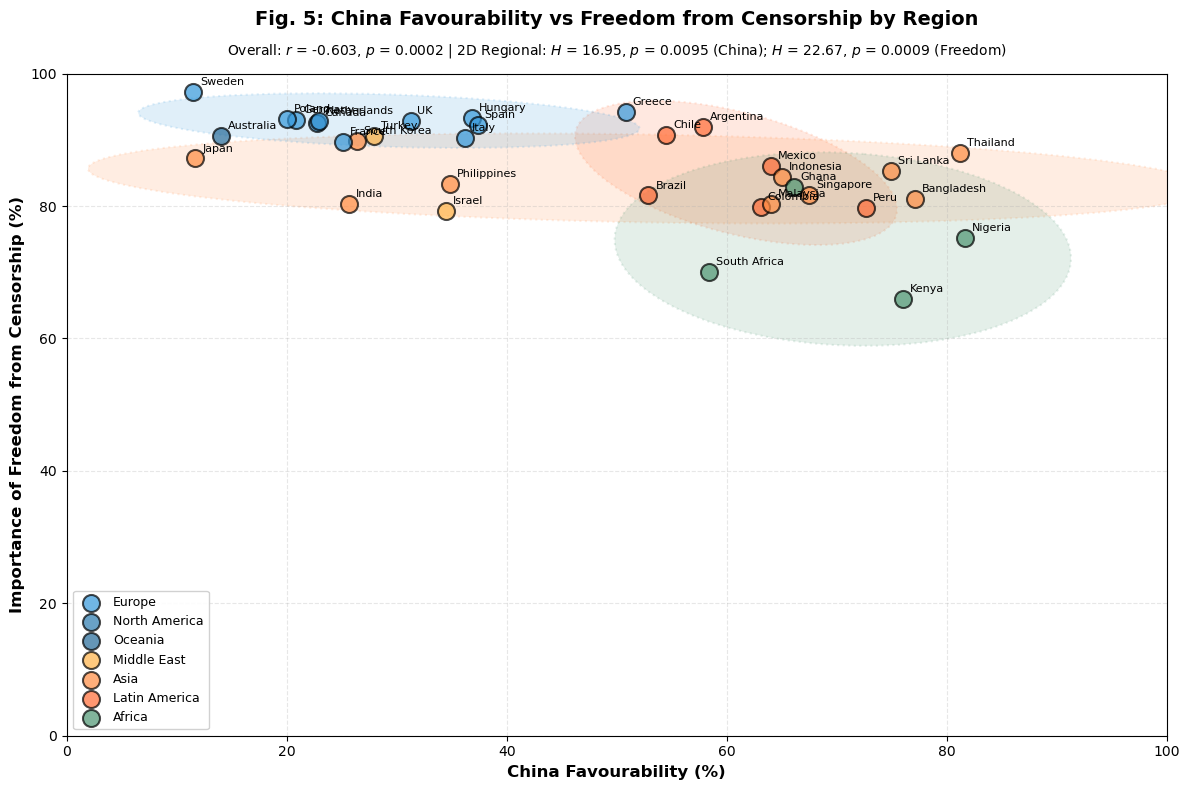

In [265]:
valid_data_china = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data_china['weight'] = pd.to_numeric(valid_data_china['weight'], errors='coerce')
valid_data_china = valid_data_china.dropna(subset=['weight', 'country_name', 'fav_china'])

china_favourability = {}
for country in sorted(valid_data_china['country_name'].unique()):
    country_data = valid_data_china[valid_data_china['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favourable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favourable_pct = (fav_china_favourable / total_weight) * 100
    
    china_favourability[country] = fav_china_favourable_pct

# Get composite freedom scores
def calc_freedom_importance(freedom_var):
    valid_data = pew[
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = freedom_important_pct
    
    return pd.Series(country_stats)

internet_scores = calc_freedom_importance('internet_freedom')
speech_scores = calc_freedom_importance('free_speech')
press_scores = calc_freedom_importance('press_freedom')

common_countries = internet_scores.index.intersection(speech_scores.index).intersection(press_scores.index)
internet_aligned = internet_scores[common_countries]
speech_aligned = speech_scores[common_countries]
press_aligned = press_scores[common_countries]

composite_scores = (internet_aligned + speech_aligned + press_aligned) / 3

# create df with china favourability + composite score
plot_df = pd.DataFrame({
    'Country': composite_scores.index,
    'China_Favourability': [china_favourability.get(country, np.nan) for country in composite_scores.index],
    'Composite_Freedom_Score': composite_scores.values,
    'Region': [region_map.get(country, 'Other') for country in composite_scores.index]
})

plot_df = plot_df.dropna()

region_colors = {
    'Europe': '#3498db',
    'North America (Canada)': '#2a7aaf',
    'Oceania (Australia)': '#246a99',
    'Middle East': '#ffb347',
    'Asia': '#ff8c42',
    'Latin America': '#ff6b35',
    'Africa': '#4c9571'
}

# Legend label mapping (to simplify region names)
legend_labels = {
    'North America (Canada)': 'North America',
    'Oceania (Australia)': 'Oceania'
}

corr_overall, p_val_overall = spearmanr(plot_df['China_Favourability'], plot_df['Composite_Freedom_Score'])

# clustering analysis

# test if regions differ in their positions using Kruskal-Wallis
region_groups_china = []
region_groups_freedom = []
region_names = []

for region in sorted(plot_df['Region'].unique()):
    region_data = plot_df[plot_df['Region'] == region]
    if len(region_data) > 0:  # Only exclude if completely empty
        region_groups_china.append(region_data['China_Favourability'].values)
        region_groups_freedom.append(region_data['Composite_Freedom_Score'].values)
        region_names.append(region)

if len(region_groups_china) > 1:
    h_china, p_china = kruskal(*region_groups_china)
    h_freedom, p_freedom = kruskal(*region_groups_freedom)
else:
    h_china, p_china, h_freedom, p_freedom = None, None, None, None

# visualisation
fig, ax = plt.subplots(figsize=(12, 8))

# confidence ellipses
def draw_confidence_ellipse(x, y, ax, color, n_std=2.0, alpha=0.15):
    """
    Draw a confidence ellipse around data points.
    n_std: number of standard deviations (default 2.0 for ~95% confidence)
    """
    if len(x) < 2:
        return
    
    # calculate mean and covariance
    mean_x = np.mean(x)
    mean_y = np.mean(y)
    cov = np.cov(x, y)
    
    # check if covariance matrix is valid (2x2)
    if cov.shape != (2, 2):
        return
    
    # calc eigenvalues and eigenvectors
    eigenvals, eigenvecs = np.linalg.eigh(cov)
    
    # check negative or zero eigenvalues 
    if np.any(eigenvals <= 0):
        return
    
    order = eigenvals.argsort()[::-1]
    eigenvals, eigenvecs = eigenvals[order], eigenvecs[:, order]
    
    angle = np.degrees(np.arctan2(*eigenvecs[:, 0][::-1]))
    
    # calculate width and height of ellipse (now safe since we checked eigenvals > 0)
    width, height = 2 * n_std * np.sqrt(eigenvals)
    
    ellipse = Ellipse(xy=(mean_x, mean_y), width=width, height=height,
                     angle=angle, alpha=alpha, facecolor=color, 
                     edgecolor=color, linewidth=1.5, linestyle=':', zorder=1)
    ax.add_patch(ellipse)

for region in plot_df['Region'].unique():
    region_data = plot_df[plot_df['Region'] == region]
    color = region_colors.get(region, 'gray')
    
    legend_label = legend_labels.get(region, region)
    
    if len(region_data) >= 3:
        x = region_data['China_Favourability'].values
        y = region_data['Composite_Freedom_Score'].values
        draw_confidence_ellipse(x, y, ax, color, n_std=2.0, alpha=0.15)
    
    ax.scatter(region_data['China_Favourability'], region_data['Composite_Freedom_Score'],
              s=150, alpha=0.7, edgecolors='black', linewidth=1.5,
              label=legend_label, color=color, zorder=3)

for idx, row in plot_df.iterrows():
    ax.annotate(row['Country'], 
               (row['China_Favourability'], row['Composite_Freedom_Score']),
               fontsize=8, color='black', alpha=1, xytext=(5, 5), textcoords='offset points')

ax.set_xlabel('China Favourability (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Importance of Freedom from Censorship (%)', fontsize=12, fontweight='bold')

title_line1 = f'Fig. 5: China Favourability vs Freedom from Censorship by Region'
title_line2 = f'Overall: $r$ = {corr_overall:.3f}, $p$ = {p_val_overall:.4f} | 2D Regional: $H$ = {h_china:.2f}, $p$ = {p_china:.4f} (China); $H$ = {h_freedom:.2f}, $p$ = {p_freedom:.4f} (Freedom)'

ax.set_title(title_line1, fontsize=14, fontweight='bold', pad=35)

ax.text(0.5, 1.02, title_line2, transform=ax.transAxes, 
        fontsize=10, ha='center', va='bottom')

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3, linestyle='--')

handles, labels = ax.get_legend_handles_labels()

desired_order = [
    'Europe',
    'North America',
    'Oceania',
    'Middle East',
    'Asia',
    'Latin America',
    'Africa'
]

ordered_handles = []
ordered_labels = []
for desired_label in desired_order:
    if desired_label in labels:
        idx = labels.index(desired_label)
        ordered_handles.append(handles[idx])
        ordered_labels.append(desired_label)

ax.legend(ordered_handles, ordered_labels, loc='lower left', framealpha=0.9, fontsize=9, ncol=1)

plt.tight_layout()
plt.show()

Fig. 5 tests whether the relationship between China favourability and the importance of freedom from censorship is correlated by regional distinctions. While *within*-region analyses revealed no significant correlations (all $p > 0.05$), Kruskal-Wallis tests demonstrated that regions do differ *between* one another, driven by distinct positions in the 2D plane: China favourability ($H = 16.953$, $p = 0.0095$); and as previously shown in Fig 4, importance of freedom from censorship ($H = 22.674$ and $p = 0.0009$). Confidence ellipses (95% confidence regions) were drawn around each region's data points to visualise the bivariate distribution and regional clustering. Spearman's rank correlation coefficient across all countries was $r = -0.603$, $p = 0.0002$. 

# Discussion 

Findings demonstrate that perceptions of China correlate with attitudes towards the importance of freedom from censorship, supporting the hypothesis that value commitments shape cross-national perceptions. Strong negative correlations between China favourability and all three freedom variables reveal an inverse relationship consistent with social identity theory: the degree to which a nation's values conflict with China's, directly corresponds with favourability, revealing patterns of alignment and opposition across the global landscape. Geographic patterns reinforce this theoretical framework, with Western liberal democracies showing both higher prioritisation of freedom from censorship and lower China favourability. Non-Western nations exhibit the inverse pattern: higher China favourability and lower freedom importance, potentially reflecting values aligned with alternative governance regimes. Furthermore, distinct patterns *between* regions - which come together to drive the overall negative correlation - act as evidence for regionally clustered value commitments. When isolating countries within the same region, correlations are not present. China's global favourability, which was far lower than that of the EU and US, suggests that despite cross-national differences, all nations on average still exhibit greater favourability towards the West (Fig. 3). This pattern could reflect the global reach of Western discourse, whereby Orientalist representations of China have been internalized beyond Western contexts. Alternatively, it might suggest that Said's framework, while valuable for understanding Western constructions of the Other, requires extension to account for how non-Western nations navigate global hierarchies. Nevertheless, it could be argued that China functions as an Other through which nations articulate their own governance values. Together, these findings indicate that the relationship between freedom values and China favourability remain closely tied to value-based identity formation.


# Limitations

Several potential limitations should be noted. First, geographic representation in the Pew dataset is uneven: while Asia contains 11 countries and Europe 10, the Middle East includes only Turkey, Tunisia, and Israel, and Africa just 4 countries. Whilst strong regional patterns were identified, categories such as 'Oceania' and 'North America' (Fig. 4) contain single countries each, potentially influencing the generalisability of regional comparisons. Second, self-reported favourability ratings may be influenced by social desirability, political climate, or media framing, particularly in countries with restricted expression. Third, whilst phrases such as  'Western liberal democracy' are used with contextual nuance, countries may diverge from expected patterns when other cultural values are considered. Future research could examine perceived versus valued freedom, or consider additional factors such as perceptions of domestic democracy. Finally, whilst a correlation is identified, the cross-national data cannot establish a causal direction between freedom values and China perceptions.

# Bibliography

Packages used: [[25]](#ref25), [[26]](#ref26), [[27]](#ref27), [[28]](#ref28), [[29]](#ref29), [[30]](#ref30)

<a id="ref1"></a>
[1] Inglehart, R., & Welzel, C. (2005). Modernization, cultural change, and democracy: The human development sequence. Cambridge University Press.

<a id="ref2"></a>
[2] Tajfel, H., & Turner, J. C. (1979). An integrative theory of intergroup conflict. In W. G. Austin & S. Worchel (Eds.), The social psychology of intergroup relations (pp. 33–47). Brooks/Cole.

<a id="ref3"></a>
[3] Clifford, J., & Marcus, G. E. (1986). Writing culture: The poetics and politics of ethnography. University of California Press.

<a id="ref4"></a>
[4] Asch, M. (2015). Anthropology, colonialism and the reflexive turn: Finding a place to stand. Anthropologica, 57(2), 481–489.

<a id="ref5"></a>
[5] Haraway, D. (1988). Situated knowledges: The science question in feminism and the privilege of partial perspective. Feminist Studies, 14(3), 575–599.

<a id="ref6"></a>
[6] Said, E. W. (1978). Orientalism. Pantheon Books.

<a id="ref7"></a>
[7] Neumann, I. B. (1999). Uses of the other: "The East" in European identity formation. University of Minnesota Press.

<a id="ref8"></a>
[8] von Blomberg, M., & Liu, C. (2025). Techno-orientalism in the US media: The case of 'China's social credit system'. Information, Communication & Society. Advance online publication. https://doi.org/10.1080/1369118X.2025.2565335

<a id="ref9"></a>
[9] Morley, D., & Robins, K. (1992). Techno-orientalism: Foreigners, phobias and futures. New Formations, 1992(16).

<a id="ref10"></a>
[10] Morley, D., & Robins, K. (1995). Techno-Orientalism: Japan panic. In Spaces of identity: Global media, electronic landscapes and cultural boundaries (pp. 147–173). Routledge.

<a id="ref11"></a>
[11] Sohn, S. H. (2008). Editor's introduction: Alien/Asian: Imagining the racialized future. MELUS, 33(4), 5–22.

<a id="ref12"></a>
[12] Shambaugh, D. (2013). China goes global: The partial power. Oxford University Press.

<a id="ref13"></a>
[13] Strub, D. (2023). Confronting the rise of digital authoritarianism. The National Bureau of Asian Research. https://www.nbr.org/publication/confronting-the-rise-of-digital-authoritarianism/

<a id="ref14"></a>
[14] China Internet Network Information Center. (2025). The 55th statistical report on China's Internet development. CNNIC. https://www.cnnic.com.cn/IDR/ReportDownloads/202505/P020250514564119130448.pdf

<a id="ref15"></a>
[15] Freedom House. (2025). China: Freedom in the World 2025. Freedom in the World 2025. Retrieved November 21, 2025, from https://freedomhouse.org/country/china/freedom-world/2025

<a id="ref16"></a>
[16] Reporters Without Borders. (n.d.). China. RSF. https://rsf.org/en/country/china

<a id="ref17"></a>
[17] Drinhausen, K., & Lee, J. (2021, June 15). The CCP in 2021: Smart governance, cyber sovereignty and tech supremacy. Mercator Institute for China Studies (MERICS). https://merics.org/en/ccp-2021-smart-governance-cyber-sovereignty-and-tech-supremacy

<a id="ref18"></a>
[18] Piore, A. (2022, September 7). Beijing's plan to control the world's data: Out-Google Google. Newsweek. https://www.newsweek.com/2022/09/16/beijings-plan-control-worlds-data-out-google-google-1740426.html

<a id="ref19"></a>
[19] Moynihan, H., & Patel, C. (2021). Restrictions on online freedom of expression in China: The domestic, regional and international implications of China's policies and practices. Chatham House. https://www.chathamhouse.org/sites/default/files/2021-03/2021-03-17-restrictions-online-freedom-expression-china-moynihan-patel.pdf

<a id="ref20"></a>
[20] King, G., Pan, J., & Roberts, M. E. (2013). How censorship in China allows government criticism but silences collective expression. American Political Science Review, 107(2), 326–343. https://doi.org/10.1017/S0003055413000014

<a id="ref21"></a>
[21] Wynn-Williams, S. (2025). Careless people: A cautionary tale of power, greed, and lost idealism. Flatiron Books

<a id="ref22"></a>
[22] Quan, E. (2022). Censorship sensing: The capabilities and implications of China's Great Firewall under Xi Jinping. Sigma: Journal of Political and International Studies, 39(1), Article 4. https://scholarsarchive.byu.edu/sigma/vol39/iss1/4

<a id="ref23"></a>
[23] Chandel, S., Zang, J., Yu, Y., Sun, J., & Zhang, Z. (2019). The Golden Shield Project of China: A decade later—An in-depth study of the Great Firewall. In 2019 International Conference on Cyber-Enabled Distributed Computing and Knowledge Discovery (CyberC) (pp. 111–119). IEEE. https://doi.org/10.1109/CYBERC.2019.00027

<a id="ref24"></a>
[24] Li, L., & Zhou, K. (2024). When content moderation is not about content: How Chinese social media platforms moderate content and why it matters. New Media & Society. Advance online publication. https://doi.org/10.1177/14614448241263933

<a id="ref25"></a>
[25] Plotly Technologies Inc. (2015). Collaborative data science. Plotly Technologies Inc. Available: https://plotly.com/python/

<a id="ref26"></a>
[26] Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90-95. https://doi.org/10.1109/MCSE.2007.55. Available: https://matplotlib.org

<a id="ref27"></a>
[27] Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., Gérard-Marchant, P., Sheppard, K., Reddy, T., Weckesser, W., Abbasi, H., Gohlke, C., & Oliphant, T. E. (2020). Array programming with NumPy. Nature, 585(7825), 357-362. https://doi.org/10.1038/s41586-020-2649-2. Available: https://numpy.org

<a id="ref28"></a>
[28] McKinney, W. (2010). Data structures for statistical computing in python. In Proceedings of the 9th Python in Science Conference, 445, 51-56. https://pandas.pydata.org. Available: https://pandas.pydata.org

<a id="ref29"></a>
[29] Met Office. (2010-2015). Cartopy: A cartographic python library with a Matplotlib interface. Available: https://scitools.org.uk/cartopy

<a id="ref30"></a>
[30] Waskom, M. L. (2021). seaborn: statistical data visualization. Journal of Open Source Software, 6(60), 3021. https://doi.org/10.21105/joss.03021. Available: https://seaborn.pydata.org